# 반도체 밸류 팩터 국면 검증 재현 노트북

이 노트북은 4주차 과제 Markdown의 요구사항에 맞춰 원천 이익·자본·시가총액으로 E/P와 B/P를 직접 계산하고, lag 적용 후 IC·분위 포트폴리오·금융 포함/제외 실험을 재현합니다.

In [1]:
from pathlib import Path
import math, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = BASE_DIR / 'input' / 'processed_data'
OUTPUT_DIR = BASE_DIR / 'output' / 'results'
SCALE = 1000.0
START_PERF = pd.Timestamp('2007-01-31')
END_PERF = pd.Timestamp('2026-06-30')

## 0. 데이터 로더

In [2]:
def nfc(text):
    return unicodedata.normalize('NFC', str(text)).strip()

def find_csv(name):
    target = nfc(name)
    for path in DATA_DIR.iterdir():
        if path.suffix.lower() == '.csv' and nfc(path.name) == target:
            return path
    raise FileNotFoundError(name)

def read_wide_csv(name):
    df = pd.read_csv(find_csv(name))
    df = df.rename(columns={df.columns[0]: 'Date'})
    df['Date'] = pd.to_datetime(df['Date'].astype(str).str.replace('.', '-', regex=False), errors='coerce')
    df = df.dropna(subset=['Date']).set_index('Date').sort_index()
    df.columns = [nfc(c) for c in df.columns]
    df = df.loc[:, ~pd.Index(df.columns).duplicated()]
    for col in df.columns:
        df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '', regex=False), errors='coerce')
    return df

def read_universe_csv(name):
    df = pd.read_csv(find_csv(name))
    return [nfc(x) for x in df.iloc[0, 1:].tolist() if nfc(x) and nfc(x).lower() != 'nan']

def read_optional_universe_csv(candidates):
    for name in candidates:
        try:
            return read_universe_csv(name), name
        except FileNotFoundError:
            continue
    return None, None

FINANCIAL_KEYWORDS = ('금융','은행','뱅크','증권','보험','생명','화재','카드','캐피탈','리스','신용','저축','종금','종합금융','스팩')
EXTRA_FINANCIAL_NAMES = {'현대해상','코리안리','SBI모기지','SBI핀테크솔루션즈'}

def make_financial_flag(columns):
    names, source = read_optional_universe_csv(['금융유니버스.csv','금융 유니버스.csv','금융업유니버스.csv','금융업 유니버스.csv','금융산업군.csv','금융 산업군.csv','은행보험증권유니버스.csv','은행 보험 증권 유니버스.csv'])
    if names is not None:
        financial_set = set(names)
        return pd.Series({c: c in financial_set for c in columns}, dtype=bool), f'DataGuide 금융 유니버스 파일 {source}', True
    flag = pd.Series({c: any(k in c for k in FINANCIAL_KEYWORDS) or c in EXTRA_FINANCIAL_NAMES for c in columns}, dtype=bool)
    return flag, '종목명 금융 키워드 fallback', False

## 1. 원천 데이터 로드 및 lag 적용

In [3]:
price = read_wide_csv('수정주가.csv')
mcap = read_wide_csv('시가총액.csv')
income = read_wide_csv('당기순이익(지배),분기.csv')
equity = read_wide_csv('자본총계(지배),분기.csv')
per = read_wide_csv('PER(IFRS-연결).csv')
pe = read_wide_csv('P:E.csv')
ism = read_wide_csv('미국 ISM.csv').iloc[:, 0]
cyclical_names = read_universe_csv('시클리컬 유니버스.csv')

manufacturing_names = read_universe_csv('제조업유니버스.csv')

common_dates = price.index.intersection(mcap.index).intersection(income.index).intersection(equity.index)
common_cols = price.columns.intersection(mcap.columns).intersection(income.columns).intersection(equity.columns)
price, mcap, income, equity = [x.loc[common_dates, common_cols] for x in [price, mcap, income, equity]]
pe = pe.reindex(index=common_dates, columns=common_cols)

per = per.reindex(index=common_dates, columns=common_cols)

def make_lagged_financial(financial):
    tmp = financial.copy()
    tmp['__quarter'] = tmp.index.to_period('Q')
    quarterly = tmp.groupby('__quarter').last()
    availability = []
    for q in quarterly.index:
        q_end_month = q.asfreq('M', how='end')
        availability.append(q_end_month + (4 if q.quarter == 4 else 3))
    quarterly.index = pd.PeriodIndex(availability, freq='M')
    months = pd.PeriodIndex(financial.index.to_period('M'), freq='M')
    all_months = pd.period_range(months.min(), months.max(), freq='M')
    lagged = quarterly.reindex(all_months).ffill().reindex(months)
    lagged.index = financial.index
    return lagged

def make_lagged_ttm_financial(financial):
    tmp = financial.copy()
    tmp['__quarter'] = tmp.index.to_period('Q')
    quarterly = tmp.groupby('__quarter').last()
    quarterly.index = pd.PeriodIndex(quarterly.index, freq='Q')
    ttm = quarterly.rolling(4).sum()
    availability = []
    for q in ttm.index:
        q_end_month = q.asfreq('M', how='end')
        availability.append(q_end_month + (4 if q.quarter == 4 else 3))
    ttm.index = pd.PeriodIndex(availability, freq='M')
    months = pd.PeriodIndex(financial.index.to_period('M'), freq='M')
    all_months = pd.period_range(months.min(), months.max(), freq='M')
    lagged = ttm.reindex(all_months).ffill().reindex(months)
    lagged.index = financial.index
    return lagged

def make_lagged_fiscal_year_sum(financial):
    tmp = financial.copy()
    tmp['__quarter'] = tmp.index.to_period('Q')
    quarterly = tmp.groupby('__quarter').last()
    quarterly.index = pd.PeriodIndex(quarterly.index, freq='Q')
    fiscal_year = quarterly.rolling(4).sum().loc[lambda x: x.index.quarter == 4]
    fiscal_year.index = pd.PeriodIndex([q.asfreq('M', how='end') + 4 for q in fiscal_year.index], freq='M')
    months = pd.PeriodIndex(financial.index.to_period('M'), freq='M')
    all_months = pd.period_range(months.min(), months.max(), freq='M')
    lagged = fiscal_year.reindex(all_months).ffill().reindex(months)
    lagged.index = financial.index
    return lagged

lag_income = make_lagged_financial(income)
lag_equity = make_lagged_financial(equity)
ttm_income = make_lagged_ttm_financial(income)
fiscal_income = make_lagged_fiscal_year_sum(income)
ep_quarterly = lag_income / (mcap * SCALE)
ep_unlagged = income / (mcap * SCALE)
ep_ttm = ttm_income / (mcap * SCALE)
ep_fiscal_year = fiscal_income / (mcap * SCALE)
ep = ep_quarterly
bp = lag_equity / (mcap * SCALE)
per_inverse = 1 / per.replace(0, np.nan)
pe_inverse = 1 / pe.replace(0, np.nan)
forward_returns = price.pct_change(fill_method=None).shift(-1)
cyc_cols = [x for x in cyclical_names if x in common_cols]
mfg_cols = [x for x in manufacturing_names if x in common_cols]
financial_flag, financial_source, financial_is_exact = make_financial_flag(common_cols)
non_fin_cols = [x for x in common_cols if not financial_flag[x]]
len(common_cols), len(cyc_cols), len(mfg_cols), int(financial_flag.sum()), financial_source, common_dates.min(), common_dates.max()

(3980,
 121,
 3527,
 441,
 '종목명 금융 키워드 fallback',
 Timestamp('2006-01-31 00:00:00'),
 Timestamp('2026-06-30 00:00:00'))

## 2. 표준화, IC, 분위 포트폴리오

In [4]:
def winsorize_row(row, lower=0.01, upper=0.99):
    valid = row.dropna()
    if len(valid) < 5:
        return row * np.nan
    return row.clip(valid.quantile(lower), valid.quantile(upper))

def zscore_cross_section(factor):
    clipped = factor.apply(winsorize_row, axis=1)
    return clipped.sub(clipped.mean(axis=1), axis=0).div(clipped.std(axis=1).replace(0, np.nan), axis=0)

def compute_ic(factor, returns, min_n=10):
    out = {}
    for date in factor.index:
        f, r = factor.loc[date], returns.loc[date]
        valid = f.notna() & r.notna()
        out[date] = f[valid].rank().corr(r[valid].rank()) if valid.sum() >= min_n else np.nan
    return pd.Series(out)

def quintile_returns(factor, returns, min_n=25):
    rows = []
    for date in factor.index:
        f, r = factor.loc[date], returns.loc[date]
        valid = f.notna() & r.notna()
        if valid.sum() < min_n:
            continue
        buckets = pd.qcut(f[valid].rank(method='first'), 5, labels=[1,2,3,4,5])
        row = {'Date': date}
        for q in [1,2,3,4,5]:
            row[f'Q{q}'] = r[buckets[buckets == q].index].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index('Date')

ep_z = zscore_cross_section(ep[cyc_cols])
bp_z = zscore_cross_section(bp[cyc_cols])
ret_cyc = forward_returns[cyc_cols]
mask = (ep_z.index >= START_PERF) & (ep_z.index <= END_PERF)
ic = pd.DataFrame({'E/P': compute_ic(ep_z, ret_cyc), 'B/P': compute_ic(bp_z, ret_cyc)}).loc[mask]
ep_q = quintile_returns(ep_z.loc[mask], ret_cyc.loc[mask])
bp_q = quintile_returns(bp_z.loc[mask], ret_cyc.loc[mask])
ic.mean(), ep_q.mean(), bp_q.mean()

(E/P    0.028084
 B/P    0.012836
 dtype: float64,
 Q1    0.017625
 Q2    0.018495
 Q3    0.017762
 Q4    0.019604
 Q5    0.018786
 dtype: float64,
 Q1    0.019634
 Q2    0.017655
 Q3    0.021537
 Q4    0.017443
 Q5    0.015802
 dtype: float64)

## 3. 성과 지표

In [5]:
def perf_metrics(ret):
    ret = ret.dropna()
    nav = (1 + ret).cumprod()
    years = len(ret) / 12
    return pd.Series({
        'months': len(ret),
        'NAV': nav.iloc[-1],
        'CAGR': nav.iloc[-1] ** (1 / years) - 1,
        'Ann.Vol': ret.std() * np.sqrt(12),
        'Sharpe': ret.mean() / ret.std() * np.sqrt(12),
        'MDD': (nav / nav.cummax() - 1).min(),
    })

summary = pd.DataFrame({
    'E/P Q5': perf_metrics(ep_q['Q5']),
    'B/P Q5': perf_metrics(bp_q['Q5']),
}).T
summary

,months,NAV,CAGR,Ann.Vol,Sharpe,MDD
E/P Q5,233.0,37.213116,0.204742,0.276143,0.816375,-0.549713
B/P Q5,233.0,17.982366,0.160452,0.284214,0.667175,-0.601163


## 3-a. E/P 정의 비교

In [6]:
def ep_definition_eval(label, factor):
    factor_z = zscore_cross_section(factor[cyc_cols])
    factor_ic = compute_ic(factor_z, ret_cyc).loc[mask]
    factor_q = quintile_returns(factor_z.loc[mask], ret_cyc.loc[mask])
    q5 = perf_metrics(factor_q['Q5'])
    return pd.Series({
        'E/P Definition': label,
        'Mean IC': factor_ic.mean(),
        'IC IR': factor_ic.mean() / factor_ic.std(),
        'Positive IC Ratio': (factor_ic > 0).mean(),
        'Q5 CAGR': q5['CAGR'],
        'Q5 Sharpe': q5['Sharpe'],
        'Q5 MDD': q5['MDD'],
    })

pd.DataFrame([
    ep_definition_eval('Quarterly lagged E/P (strategy)', ep_quarterly),
    ep_definition_eval('TTM lagged E/P', ep_ttm),
    ep_definition_eval('Fiscal-year lagged E/P', ep_fiscal_year),
])

,E/P Definition,Mean IC,IC IR,Positive IC Ratio,Q5 CAGR,Q5 Sharpe,Q5 MDD
0,Quarterly lagged E/P (strategy),0.028084,0.219854,0.576923,0.204742,0.816375,-0.549713
1,TTM lagged E/P,0.024454,0.171976,0.581197,0.155427,0.682814,-0.636155
2,Fiscal-year lagged E/P,0.021137,0.140759,0.529915,0.157155,0.662954,-0.651246


## 3-b. PER 검증

In [7]:
per_cols = per_inverse.notna().sum()[lambda s: s > 0].index.tolist()
validation_name = per_cols[0]
valid_per = per_inverse[validation_name].notna() & ep_fiscal_year[validation_name].notna()
valid_per_ttm = per_inverse[validation_name].notna() & ep_ttm[validation_name].notna()
valid_pe = pe_inverse[validation_name].notna() & ep_unlagged[validation_name].notna()
pd.DataFrame({
    'Check': ['Fiscal-year lagged E/P vs 1/PER', 'TTM lagged E/P vs 1/PER', 'Quarterly unlagged E/P vs 1/P:E', 'Quarterly lagged E/P vs 1/P:E'],
    'Median Abs Diff': [
        (ep_fiscal_year.loc[valid_per, validation_name] - per_inverse.loc[valid_per, validation_name]).abs().median(),
        (ep_ttm.loc[valid_per_ttm, validation_name] - per_inverse.loc[valid_per_ttm, validation_name]).abs().median(),
        (ep_unlagged.loc[valid_pe, validation_name] - pe_inverse.loc[valid_pe, validation_name]).abs().median(),
        (ep_quarterly.loc[valid_pe, validation_name] - pe_inverse.loc[valid_pe, validation_name]).abs().median(),
    ],
    'Correlation': [
        ep_fiscal_year.loc[valid_per, validation_name].corr(per_inverse.loc[valid_per, validation_name]),
        ep_ttm.loc[valid_per_ttm, validation_name].corr(per_inverse.loc[valid_per_ttm, validation_name]),
        ep_unlagged.loc[valid_pe, validation_name].corr(pe_inverse.loc[valid_pe, validation_name]),
        ep_quarterly.loc[valid_pe, validation_name].corr(pe_inverse.loc[valid_pe, validation_name]),
    ],
    'Coverage Obs': [valid_per.sum(), valid_per_ttm.sum(), valid_pe.sum(), valid_pe.sum()],
})

,Check,Median Abs Diff,Correlation,Coverage Obs
0,Fiscal-year lagged E/P vs 1/PER,0.012329,0.996320,102
1,TTM lagged E/P vs 1/PER,0.019710,0.792112,102
2,Quarterly unlagged E/P vs 1/P:E,0.003296,0.979216,243
3,Quarterly lagged E/P vs 1/P:E,0.005597,0.243426,243


## 4. 금융 포함/제외 대조 실험

In [8]:
# A: 전체 시장, B: 금융 제외. 제조업 유니버스는 부정확한 근사로 참고만 확인.
manufacturing_flag = pd.Series({c: c in set(mfg_cols) for c in common_cols})
financial_flag = financial_flag.reindex(common_cols).fillna(False)
non_fin_cols = [c for c in common_cols if not financial_flag[c]]

def top_n_returns(factor, returns, mcap, universe_cols=None, candidate_cols=None, share_reference=None, top_mcap=300, top_n=20):
    out, ref_share = {}, {}
    base_allowed = pd.Index(universe_cols) if universe_cols is not None else pd.Index(factor.columns)
    candidate_allowed = pd.Index(candidate_cols) if candidate_cols is not None else None
    for date in factor.index:
        base = mcap.loc[date, base_allowed.intersection(mcap.columns)].dropna().sort_values(ascending=False).head(top_mcap).index
        candidates_index = base if candidate_allowed is None else base.intersection(candidate_allowed)
        f = factor.loc[date, candidates_index.intersection(factor.columns)]
        r = returns.loc[date, f.index]
        valid = f.notna() & r.notna()
        cand = f[valid]
        if len(cand) < top_n:
            continue
        selected = cand.sort_values(ascending=False).head(top_n).index
        out[date] = returns.loc[date, selected].mean()
        ref_share[date] = share_reference.reindex(selected).fillna(False).mean() if share_reference is not None else np.nan
    return pd.Series(out), pd.Series(ref_share)

ep_a, ep_a_fin_share = top_n_returns(ep, forward_returns, mcap, share_reference=financial_flag)
ep_b, _ = top_n_returns(ep, forward_returns, mcap, candidate_cols=non_fin_cols)
bp_a, bp_a_fin_share = top_n_returns(bp, forward_returns, mcap, share_reference=financial_flag)
bp_b, _ = top_n_returns(bp, forward_returns, mcap, candidate_cols=non_fin_cols)
ep_mfg, _ = top_n_returns(ep, forward_returns, mcap, candidate_cols=mfg_cols)
bp_mfg, _ = top_n_returns(bp, forward_returns, mcap, candidate_cols=mfg_cols)
pd.DataFrame({'E/P A 전체': perf_metrics(ep_a.loc[START_PERF:END_PERF]), 'E/P B 금융 제외': perf_metrics(ep_b.loc[START_PERF:END_PERF]), 'B/P A 전체': perf_metrics(bp_a.loc[START_PERF:END_PERF]), 'B/P B 금융 제외': perf_metrics(bp_b.loc[START_PERF:END_PERF]), 'E/P 제조업 참고': perf_metrics(ep_mfg.loc[START_PERF:END_PERF]), 'B/P 제조업 참고': perf_metrics(bp_mfg.loc[START_PERF:END_PERF])}).T

,months,NAV,CAGR,Ann.Vol,Sharpe,MDD
E/P A 전체,233.0,4.570142,0.081404,0.239963,0.449072,-0.561908
E/P B 금융 제외,233.0,4.638722,0.082233,0.246983,0.445816,-0.557779
B/P A 전체,233.0,4.598065,0.081743,0.249534,0.439789,-0.522594
B/P B 금융 제외,233.0,5.388844,0.090620,0.256940,0.466736,-0.493466
E/P 제조업 참고,233.0,5.313111,0.089826,0.245332,0.475605,-0.529654
B/P 제조업 참고,233.0,5.573697,0.092516,0.256371,0.474119,-0.512358


## 5. 그래프

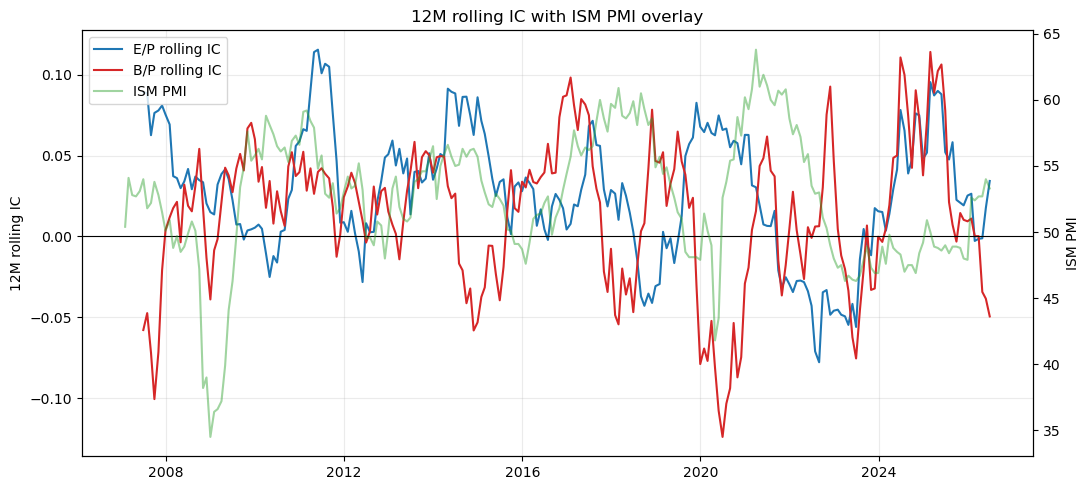

In [9]:
rolling_ic = ic.rolling(12, min_periods=6).mean()
ism_plot = ism.loc[rolling_ic.index.min():rolling_ic.index.max()].dropna()

fig, ax1 = plt.subplots(figsize=(11, 5))
ep_col = next(col for col in rolling_ic.columns if col.startswith('E/P'))
ax1.plot(rolling_ic.index, rolling_ic[ep_col], label=f'{ep_col} rolling IC', color='tab:blue')
ax1.plot(rolling_ic.index, rolling_ic['B/P'], label='B/P rolling IC', color='tab:red')
ax1.axhline(0, color='black', linewidth=0.8)
ax1.set_ylabel('12M rolling IC')
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()
ax2.plot(ism_plot.index, ism_plot.values, label='ISM PMI', color='tab:green', alpha=0.45)
ax2.set_ylabel('ISM PMI')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
ax1.set_title('12M rolling IC with ISM PMI overlay')
fig.tight_layout()
plt.show()